# Gallstone model-improvement study — offline Kaggle notebook

**Development only:** This experiment uses the same 319 records and follows examination of prior scores. Results cannot be presented as an untouched confirmatory test. It adds a 5×3 nested selection of regularized logistic/SVM variants, a second split seed, inner-training-only threshold selection, paired baseline, conditional bootstrap, publication-resolution figures, and a full-data research model. No fabricated 95% score or comparison with unmatched papers.

No UCI download or separate dataset upload required; the exact user-supplied CSV is embedded and checked by SHA256. Kaggle CPU is sufficient. `Run All` and retrieve the generated `gallstone_upgrade_exploratory.zip` from Outputs. Dependencies: numpy, pandas, scipy, scikit-learn, matplotlib, joblib (normally installed on Kaggle).

In [1]:
import os, json, hashlib, base64, zlib, warnings, time, shutil
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import joblib
from sklearn.base import BaseEstimator, TransformerMixin
from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import RobustScaler
from sklearn.feature_selection import SelectKBest, f_classif, VarianceThreshold
from sklearn.linear_model import LogisticRegression
from sklearn.svm import SVC
from sklearn.model_selection import StratifiedKFold, cross_val_score, cross_val_predict
from sklearn.metrics import (roc_auc_score, accuracy_score, f1_score, confusion_matrix,
                             matthews_corrcoef, roc_curve, precision_recall_curve, average_precision_score,
                             brier_score_loss, balanced_accuracy_score, precision_score, recall_score)
from sklearn.calibration import calibration_curve
from scipy.stats import binomtest
warnings.filterwarnings('ignore',category=FutureWarning)
SEED = 42
OUT = (Path('/kaggle/working') if Path('/kaggle/working').exists() else Path.cwd())/'gallstone_upgrade_exploratory'
OUT.mkdir(parents=True,exist_ok=True)
print('Outputs:',OUT,'| Exploratory nested CV; not independent validation')

Outputs: C:\Users\user\Desktop\GullStone\gallstone_upgrade_exploratory | Exploratory nested CV; not independent validation


In [2]:
# Verified byte-for-byte user-supplied CSV; no UCI request or Kaggle Input required.
_B64 = '...'
RAW = zlib.decompress(base64.b64decode(_B64))
EXPECTED_SHA256 = 'f8aaa71e4e6caff48b8131c8113eeedf68c3bef827ad18790a067ae1f80d5ad7'
assert hashlib.sha256(RAW).hexdigest() == EXPECTED_SHA256, 'Dataset fingerprint mismatch!'
(OUT/'verified_dataset.csv').write_bytes(RAW)
df = pd.read_csv(OUT/'verified_dataset.csv')
assert df.shape == (319,39), f'Unexpected dataset shape: {df.shape}'
assert df['Gallstone'].dropna().isin([0,1]).all()
y = (df.pop('Gallstone').to_numpy() == 0).astype(int)  # UCI raw zero: disease-present
X = df.rename(columns={'Triglycerides':'Triglyceride','Visceral_Fat_Area':'VFA','Visceral_Muscle_Area':'VMA'})
assert sum(y==1)==158 and sum(y==0)==161
assert not X.duplicated().any(), 'Identical rows found: group-aware CV required.'
assert not X.isna().any().any(), 'Unexpected missing data; inspect original.'
data_audit={'rows':len(y),'input_features':X.shape[1], 'gallstone_present':int(y.sum()),
 'gallstone_absent':int((1-y).sum()),'csv_sha256':EXPECTED_SHA256,
 'note':'Dataset embedded from original user-uploaded dataset-uci.csv; not downloaded anew'}
(OUT/'data_audit.json').write_text(json.dumps(data_audit,indent=2))
print('Audit:',data_audit)

Audit: {'rows': 319, 'input_features': 38, 'gallstone_present': 158, 'gallstone_absent': 161, 'csv_sha256': 'f8aaa71e4e6caff48b8131c8113eeedf68c3bef827ad18790a067ae1f80d5ad7', 'note': 'Dataset embedded from original user-uploaded dataset-uci.csv; not downloaded anew'}


## Fold-local feature engineering and training-only preprocessing

In [3]:
class ClinicalFeatures(BaseEstimator,TransformerMixin):
    def __init__(self,enabled=True): self.enabled=enabled
    def fit(self,X,y=None):
        self.input_features_=list(X.columns)
        return self
    def transform(self,X):
        D=X.copy() if isinstance(X,pd.DataFrame) else pd.DataFrame(X,columns=self.input_features_)
        if not self.enabled: return D
        def pair(a,b,n,product=False):
            if a in D.columns and b in D.columns:
                x=D[a].astype(float); z=D[b].astype(float)
                D[n]=(x*z) if product else (x / z.where(z.abs()>1e-8,np.nan))
        for a,b,n in [('AST','ALT','AST_ALT_ratio'),('LDL','HDL','LDL_HDL_ratio'),
                     ('Triglyceride','HDL','TG_HDL_ratio'),('CRP','HGB','CRP_HGB_ratio'),
                     ('ECW','TBW','ECW_TBW_ratio'),('Total_Fat','Muscle_Mass','Fat_Muscle_ratio'),
                     ('VFA','VMA','VFA_VMA_ratio')]: pair(a,b,n)
        for a,b,n in [('CRP','HGB','CRP_times_HGB'),('Vitamin_D','Hyperlipidemia','VitD_times_Hyperlip'),
                     ('BMI','VFA','BMI_times_VFA'),('Age','CRP','Age_times_CRP'),
                     ('Glucose','DM','Glucose_times_DM')]:pair(a,b,n,True)
        return D.replace([np.inf,-np.inf],np.nan)
    def get_feature_names_out(self,input_features=None):
        data=pd.DataFrame(np.ones((1,len(self.input_features_))),columns=self.input_features_)
        return np.array(self.transform(data).columns,dtype=object)

class ClipByTrainingQuantiles(BaseEstimator,TransformerMixin):
    def __init__(self,lower=0.01,upper=0.99): self.lower=lower;self.upper=upper
    def fit(self,X,y=None):
        self.lo_=np.nanquantile(np.asarray(X,dtype=float),self.lower,axis=0)
        self.hi_=np.nanquantile(np.asarray(X,dtype=float),self.upper,axis=0)
        return self
    def transform(self,X):return np.clip(np.asarray(X,dtype=float),self.lo_,self.hi_)

In [4]:
def model(name,fe,k,C=1):
 clf=(SVC(C=C,kernel='rbf',probability=True,random_state=42) if name=='SVM' else
      LogisticRegression(C=C,solver='lbfgs',max_iter=3000))
 steps=[('fe',ClinicalFeatures(enabled=fe)),('impute',SimpleImputer(strategy='median')),
 ('clip',ClipByTrainingQuantiles()),('variance',VarianceThreshold(threshold=0.0))]
 if k!='all': steps.append(('select',SelectKBest(score_func=f_classif,k=k)))
 steps.extend([('scale',RobustScaler()),('clf',clf)])
 return Pipeline(steps)
# Locked menu: only compared within each outer-training fold.
candidates=[('LR',False,'all',.1),('LR',False,'all',1),('LR',True,'all',.1),
 ('LR',True,'all',1),('LR',True,'all',10),('LR',True,22,.1),
 ('LR',True,22,1),('LR',True,22,10),('LR',True,12,1),
 ('SVM',True,'all',.1),('SVM',True,'all',1),('SVM',True,22,1)]

def cutoff_train(ytrue,probs):
 # Training-side OOF tuning, never inspect outer held-out labels/probabilities.
 vals=np.unique(np.r_[0,.5,1,probs]); mids=(vals[:-1]+vals[1:])/2
 accuracy=np.array([np.mean((probs>=t)==ytrue) for t in mids]);mx=np.max(accuracy)
 return float(mids[np.flatnonzero(accuracy==mx)[np.argmin(abs(mids[accuracy==mx]-.5))]])



## Nested evaluation: two sensitivity partitions, fixed candidate menu, 3-fold inner selection

In [5]:
out=[]; oof_dump=[]; t0=time.time()
for seed in (42,123):
 oof=np.full(len(y),np.nan);oof_lr=np.full(len(y),np.nan);oo_thr=np.full(len(y),np.nan)
 for fold,(tr,te) in enumerate(StratifiedKFold(5,shuffle=True,random_state=seed).split(X,y),1):
  inner=list(StratifiedKFold(3,shuffle=True,random_state=seed+fold).split(X.iloc[tr],y[tr]))
  candidate_scores=[]
  for config in candidates:
   pipe=model(*config)
   score=np.mean(cross_val_score(pipe,X.iloc[tr],y[tr],cv=inner,scoring='roc_auc',n_jobs=1,error_score='raise'))
   candidate_scores.append(score)
  wi=int(np.argmax(candidate_scores)); selected=candidates[wi];pipe=model(*selected)
  training_proba=cross_val_predict(pipe,X.iloc[tr],y[tr],cv=inner,method='predict_proba',n_jobs=1)[:,1]
  threshold=cutoff_train(y[tr],training_proba)
  pipe.fit(X.iloc[tr],y[tr]); p=pipe.predict_proba(X.iloc[te])[:,1]
  baseline=model('LR',True,22,1);baseline.fit(X.iloc[tr],y[tr]);plr=baseline.predict_proba(X.iloc[te])[:,1]
  oof[te]=p;oof_lr[te]=plr;oo_thr[te]=threshold
  out.append({'seed':seed,'outer_fold':fold,'selected':str(selected),
   'inner_selected_auc':candidate_scores[wi], 'heldout_auc':roc_auc_score(y[te],p),
   'heldout_auc_lr_baseline':roc_auc_score(y[te],plr),
   'heldout_accuracy_05':accuracy_score(y[te],p>=.5),
   'heldout_accuracy_training_threshold':accuracy_score(y[te],p>=threshold),
   'train_selected_threshold':threshold,'heldout_lr_accuracy_05':accuracy_score(y[te],plr>=.5)})
  print(f'seed={seed} fold={fold} selected={selected} inner={candidate_scores[wi]:.4f} outerAUC={out[-1]["heldout_auc"]:.4f} ACC={out[-1]["heldout_accuracy_05"]:.4f}',flush=True)
 for idx in range(len(y)):
  oof_dump.append({'seed':seed,'row_id':idx,'y':int(y[idx]),'nested_probability':float(oof[idx]),'fixed_lr_probability':float(oof_lr[idx]),'training_threshold':float(oo_thr[idx])})
 print('SEED',seed,'NESTED_POOLED_AUC',roc_auc_score(y,oof),'ACC',accuracy_score(y,oof>=.5),'ACC_TRAIN_THRESHOLD',accuracy_score(y,oof>=oo_thr),'FIXED_LR_AUC',roc_auc_score(y,oof_lr),'FIXED_LR_ACC',accuracy_score(y,oof_lr>=.5),'elapsed',time.time()-t0,flush=True)
out=pd.DataFrame(out);pd.DataFrame(oof_dump).to_csv(OUT/'nested_oof_predictions.csv',index=False)
out.to_csv(OUT/'nested_fold_results.csv',index=False)
print('SUMMARY:')
print(out[['heldout_auc','heldout_auc_lr_baseline','heldout_accuracy_05','heldout_accuracy_training_threshold','heldout_lr_accuracy_05']].agg(['mean','std']).to_string())


seed=42 fold=1 selected=('LR', True, 'all', 10) inner=0.8896 outerAUC=0.9189 ACC=0.8125


seed=42 fold=2 selected=('LR', True, 'all', 1) inner=0.8909 outerAUC=0.8506 ACC=0.7656


seed=42 fold=3 selected=('LR', True, 'all', 1) inner=0.8876 outerAUC=0.9336 ACC=0.8594


seed=42 fold=4 selected=('LR', True, 22, 10) inner=0.9107 outerAUC=0.8330 ACC=0.8125


seed=42 fold=5 selected=('LR', True, 'all', 1) inner=0.8874 outerAUC=0.9506 ACC=0.8571


...

seed=123 fold=3 selected=('LR', True, 'all', 0.1) inner=0.8804 outerAUC=0.8213 ACC=0.7500


seed=123 fold=4 selected=('LR', True, 'all', 1) inner=0.8758 outerAUC=0.9189 ACC=0.8594


seed=123 fold=5 selected=('LR', True, 'all', 1) inner=0.8976 outerAUC=0.8962 ACC=0.8095


SEED 123 NESTED_POOLED_AUC 0.8855649029011715 ACC 0.8181818181818182 ACC_TRAIN_THRESHOLD 0.8119122257053292 FIXED_LR_AUC 0.8946458054878529 FIXED_LR_ACC 0.8244514106583072 elapsed 21.440494775772095


SUMMARY:
      heldout_auc  heldout_auc_lr_baseline  heldout_accuracy_05  heldout_accuracy_training_threshold  heldout_lr_accuracy_05
mean     0.889733                 0.883825             0.819792                             0.810342                0.810565
std      0.047279                 0.043366             0.050503                             0.052379                0.060459


## Honest summaries and conditional uncertainty

In [6]:
# Aggregate scores, one prediction per patient per 5-fold seed.
fold_stats=out[['heldout_auc','heldout_auc_lr_baseline','heldout_accuracy_05',
                'heldout_accuracy_training_threshold','heldout_lr_accuracy_05']].agg(['mean','std'])
fold_stats.to_csv(OUT/'summary_fold_statistics.csv')
print(fold_stats.to_string())
by_seed=[]
oof_table=pd.DataFrame(oof_dump)
for seed, part in oof_table.groupby('seed'):
 part=part.sort_values('row_id'); yt=part.y.to_numpy(); p=part.nested_probability.to_numpy()
 base=part.fixed_lr_probability.to_numpy();threshold=part.training_threshold.to_numpy()
 by_seed.append({'seed':int(seed),'nested_pooled_auc':roc_auc_score(yt,p),
 'nested_pooled_accuracy_05':accuracy_score(yt,p>=.5),
 'nested_pooled_accuracy_train_threshold':accuracy_score(yt,p>=threshold),
 'baseline_pooled_auc':roc_auc_score(yt,base),
 'baseline_pooled_accuracy':accuracy_score(yt,base>=.5),
 'nested_f1':f1_score(yt,p>=.5),'nested_mcc':matthews_corrcoef(yt,p>=.5),
 'nested_sensitivity':recall_score(yt,p>=.5),'nested_specificity':float(((p<.5)&(yt==0)).sum()/max((yt==0).sum(),1)),
 'nested_average_precision':average_precision_score(yt,p),'nested_brier':brier_score_loss(yt,p)})
per_seed=pd.DataFrame(by_seed);per_seed.to_csv(OUT/'pooled_per_seed.csv',index=False)
print(per_seed[['seed','nested_pooled_auc','nested_pooled_accuracy_05','baseline_pooled_auc','baseline_pooled_accuracy']].to_string(index=False))

# Conditional stratified bootstrap of OOF predictions on seed 42; does NOT refit tuning or measure external validation.
rng=np.random.default_rng(470);part=oof_table.query('seed == 42').sort_values('row_id')
yt=part.y.to_numpy();p=part.nested_probability.to_numpy();b=part.fixed_lr_probability.to_numpy()
bootstrap=[]
for iteration in range(2000):
 idx=np.r_[rng.choice(np.flatnonzero(yt==0),sum(yt==0),replace=True),
           rng.choice(np.flatnonzero(yt==1),sum(yt==1),replace=True)]
 bootstrap.append((roc_auc_score(yt[idx],p[idx]),accuracy_score(yt[idx],p[idx]>=.5),
                   roc_auc_score(yt[idx],p[idx])-roc_auc_score(yt[idx],b[idx])))
bootstrap=np.asarray(bootstrap)
ci={'auc_95_percent_conditional':[float(x) for x in np.quantile(bootstrap[:,0],[.025,.975])],
 'accuracy_95_percent_conditional':[float(x) for x in np.quantile(bootstrap[:,1],[.025,.975])],
 'paired_auc_delta_95_percent_conditional':[float(x) for x in np.quantile(bootstrap[:,2],[.025,.975])],
 'warning':'Conditional on already fitted cross-validated predictions; model discovery reused dataset; not a confirmatory CI.'}
(OUT/'bootstrap_exploratory_ci.json').write_text(json.dumps(ci,indent=2))
print('Exploratory conditional bootstrap:',ci)


      heldout_auc  heldout_auc_lr_baseline  heldout_accuracy_05  heldout_accuracy_training_threshold  heldout_lr_accuracy_05
mean     0.889733                 0.883825             0.819792                             0.810342                0.810565
std      0.047279                 0.043366             0.050503                             0.052379                0.060459
 seed  nested_pooled_auc  nested_pooled_accuracy_05  baseline_pooled_auc  baseline_pooled_accuracy
   42           0.896140                   0.821317             0.869644                  0.796238
  123           0.885565                   0.818182             0.894646                  0.824451


Exploratory conditional bootstrap: {'auc_95_percent_conditional': [0.8605590062111801, 0.9295964698482586], 'accuracy_95_percent_conditional': [0.7774294670846394, 0.8620689655172413], 'paired_auc_delta_95_percent_conditional': [0.002432384621432371, 0.05240486673480622], 'warning': 'Conditional on already fitted cross-validated predictions; model discovery reused dataset; not a confirmatory CI.'}


## Visual results from held-out predictions (not in-sample scores)

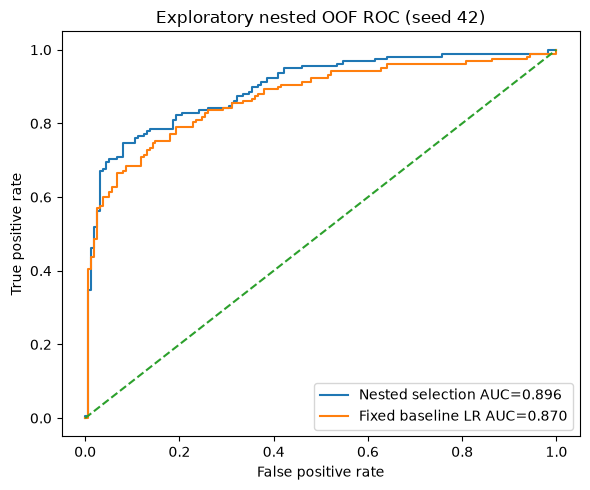

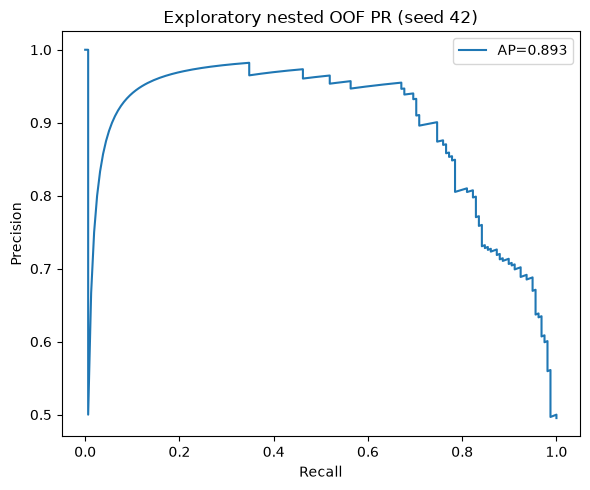

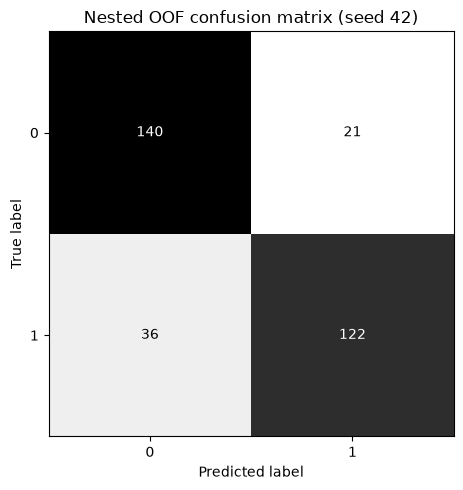

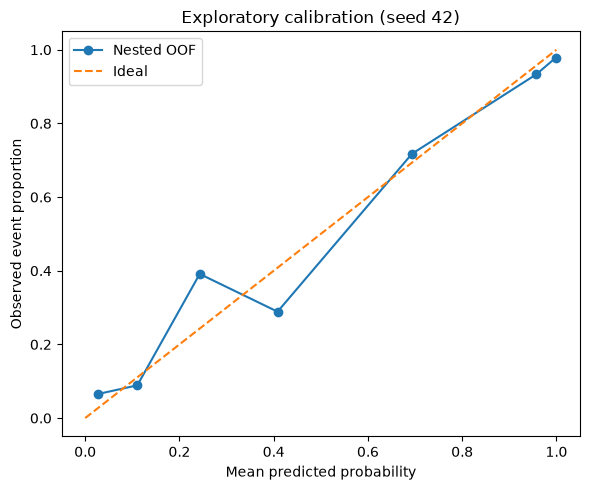

In [7]:
# Saved figures from seed-42 held-out predictions only. The other seed is a sensitivity replication, not an external cohort.
from sklearn.metrics import ConfusionMatrixDisplay
part=oof_table.query('seed == 42').sort_values('row_id')
yt=part.y.to_numpy();p=part.nested_probability.to_numpy();b=part.fixed_lr_probability.to_numpy()
fig,ax=plt.subplots(figsize=(6,5))
for name,score in [('Nested selection',p),('Fixed baseline LR',b)]:
 fpr,tpr,_=roc_curve(yt,score);ax.plot(fpr,tpr,label=f'{name} AUC={roc_auc_score(yt,score):.3f}')
ax.plot([0,1],[0,1],'--');ax.set(xlabel='False positive rate',ylabel='True positive rate',title='Exploratory nested OOF ROC (seed 42)');ax.legend()
fig.tight_layout();fig.savefig(OUT/'roc_seed42.png',dpi=300);fig.savefig(OUT/'roc_seed42.pdf');plt.show();plt.close(fig)
fig,ax=plt.subplots(figsize=(6,5));pr,rc,_=precision_recall_curve(yt,p)
ax.plot(rc,pr,label=f'AP={average_precision_score(yt,p):.3f}')
ax.set(xlabel='Recall',ylabel='Precision',title='Exploratory nested OOF PR (seed 42)');ax.legend()
fig.tight_layout();fig.savefig(OUT/'pr_seed42.png',dpi=300);fig.savefig(OUT/'pr_seed42.pdf');plt.show();plt.close(fig)
fig,ax=plt.subplots(figsize=(5,5)); ConfusionMatrixDisplay.from_predictions(yt,p>=.5,labels=[0,1],ax=ax,cmap='Greys',colorbar=False)
ax.set_title('Nested OOF confusion matrix (seed 42)');fig.tight_layout();fig.savefig(OUT/'confusion_seed42.png',dpi=300);plt.show();plt.close(fig)
true,pred=calibration_curve(yt,p,n_bins=7,strategy='quantile')
fig,ax=plt.subplots(figsize=(6,5));ax.plot(pred,true,'o-',label='Nested OOF');ax.plot([0,1],[0,1],'--',label='Ideal')
ax.set(xlabel='Mean predicted probability',ylabel='Observed event proportion',title='Exploratory calibration (seed 42)');ax.legend()
fig.tight_layout();fig.savefig(OUT/'calibration_seed42.png',dpi=300);plt.show();plt.close(fig)


## Training-only final research model and output ZIP

In [8]:
# Full-data model training is for future research use, NOT an independent performance measurement.
all_inner=list(StratifiedKFold(3,shuffle=True,random_state=SEED+777).split(X,y))
full_scores=[]
for cfg in candidates:
 full_scores.append(float(np.mean(cross_val_score(model(*cfg),X,y,cv=all_inner,scoring='roc_auc',n_jobs=1))))
best_cfg=candidates[int(np.argmax(full_scores))]
final_estimator=model(*best_cfg).fit(X,y)
joblib.dump(final_estimator,OUT/'final_model_NOT_EXTERNALLY_VALIDATED.joblib')
(OUT/'final_model_selection.json').write_text(json.dumps({'configuration':best_cfg,
 'inner_CV_mean_auc_training_only':max(full_scores),
 'warning':'Full-data training/selection is NOT external or independent validation.'},indent=2))
report=f"""# Gallstone: exploratory model-improvement results (not a finished journal paper)

Dataset: {len(y)} records, {X.shape[1]} original predictors; disease-positive n={int(y.sum())}. SHA256: {EXPECTED_SHA256}.

After inspecting the previous user's nested results, we tested new linear/nonlinear model candidates. These runs re-use the same dataset and must be presented as **exploratory development**, not an untouched confirmatory test.

Nested CV: two stratified 5-fold partitions (seeds 42 and 123). Within each outer training fold, candidate selection uses internal 3-fold ROC-AUC; feature engineering, clipping, imputation, scaling and supervised selection happen in training folds. Every outer fold has held-out predictions. Default threshold 0.5 is evaluated separately from thresholds selected on inner training OOF predictions.

Mean of ten outer-fold AUCs: {out.heldout_auc.mean():.4f}; mean outer-fold accuracy: {out.heldout_accuracy_05.mean():.4f}. Per-seed pooled AUCs: {per_seed.nested_pooled_auc.iloc[0]:.4f} and {per_seed.nested_pooled_auc.iloc[1]:.4f}. Mean outer-fold fixed-LR baseline AUC: {out.heldout_auc_lr_baseline.mean():.4f}. Seed-42 conditional bootstrap 95% CI for AUC: {ci['auc_95_percent_conditional']}.

IMPORTANT: 10 folds are **not 10 independent cohorts**. No prospective or external dataset has been used. Repeated development on this same dataset makes improvement claims and conventional confidence intervals optimistic. The paired baseline comparison is descriptive. This result does not establish superiority to a previous paper or reach 95% AUC/accuracy. Clinical deployment is unsupported.

For a manuscript: first freeze the method and evaluate with a truly independent, preferably external cohort, reproduce relevant baselines on exactly the same split, document feature definitions and dataset licensing, and provide ethics and clinical validation statements where applicable.
"""
(OUT/'README_RESULTS_EXPLORATORY.md').write_text(report,encoding='utf-8')
(OUT/'run_status.json').write_text(json.dumps({'status':'COMPLETE_EXPLORATORY_INTERNAL_ONLY','dataset_verified':True,
 'outer_partitions':[42,123],'outer_folds_per_partition':5,'candidate_count':len(candidates),
 'complete_oof_rows':len(oof_dump),'full_data_model_not_tested_externally':True},indent=2))
archive=shutil.make_archive(str(OUT),'zip',root_dir=OUT.parent,base_dir=OUT.name)
print('COMPLETE EXPLORATORY RUN | zip:',archive)
print('Not a fresh independent evaluation. No 95% performance claim.')


COMPLETE EXPLORATORY RUN | zip: C:\Users\user\Desktop\GullStone\gallstone_upgrade_exploratory.zip
Not a fresh independent evaluation. No 95% performance claim.
